In [ ]:
# ============================================================
# BAGIAN 1 - IMPORT LIBRARY
# ============================================================

import os
import zipfile
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

print("Library berhasil di-import.")

Library berhasil di-import.


In [ ]:
# ============================================================
# BAGIAN 2 - UPLOAD DATASET
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive berhasil terhubung.")

Mounted at /content/drive
Google Drive berhasil terhubung.


In [ ]:
DRIVE_PATH = "/content/drive/MyDrive"

zip_files = []

print("Mencari IMSFD.zip di Google Drive...")
print("Mohon tunggu...")

for root, dirs, files in os.walk(DRIVE_PATH):

    for file in files:

        if file.lower() == "imsfd.zip":

            full_path = os.path.join(
                root,
                file
            )

            zip_files.append(
                full_path
            )


print("\nHasil pencarian:")

if len(zip_files) == 0:

    print("IMSFD.zip tidak ditemukan.")

else:

    for i, path in enumerate(
        zip_files,
        start=1
    ):

        print(
            f"{i}. {path}"
        )

Mencari IMSFD.zip di Google Drive...
Mohon tunggu...

Hasil pencarian:
1. /content/drive/MyDrive/IMSFD.zip


In [ ]:
if len(zip_files) == 0:

    raise FileNotFoundError(
        "IMSFD.zip tidak ditemukan di Google Drive."
    )

elif len(zip_files) > 1:

    print(
        "Ditemukan lebih dari satu IMSFD.zip:"
    )

    for i, path in enumerate(
        zip_files,
        start=1
    ):
        print(
            f"{i}. {path}"
        )

    ZIP_PATH = zip_files[0]

else:

    ZIP_PATH = zip_files[0]


print("\nZIP dataset yang digunakan:")
print(ZIP_PATH)

print(
    "\nUkuran file:"
)

file_size_gb = (
    os.path.getsize(ZIP_PATH)
    / (1024 ** 3)
)

print(
    f"{file_size_gb:.2f} GB"
)


ZIP dataset yang digunakan:
/content/drive/MyDrive/IMSFD.zip

Ukuran file:
5.83 GB


In [ ]:
# ============================================================
# BAGIAN 3 - EXTRACT DATASET
# ============================================================

EXTRACT_PATH = "/content"

print("=" * 70)
print("EXTRACT DATASET IMSFD")
print("=" * 70)

print(
    "\nZIP:"
)

print(ZIP_PATH)

print(
    "\nMemulai proses extract..."
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zip_ref:

    zip_ref.extractall(
        EXTRACT_PATH
    )

print(
    "\nExtract selesai."
)

EXTRACT DATASET IMSFD

ZIP:
/content/drive/MyDrive/IMSFD.zip

Memulai proses extract...

Extract selesai.


In [ ]:
possible_paths = [
    "/content/IMSFD",
    "/content/imsfd"
]

DATASET_PATH = None

for path in possible_paths:

    if not os.path.exists(path):
        continue

    required_subsets = [
        "A1",
        "A2",
        "B1"
    ]

    if all(
        os.path.exists(
            os.path.join(
                path,
                subset
            )
        )
        for subset in required_subsets
    ):

        DATASET_PATH = path
        break


# Jika belum ditemukan di /content/IMSFD,
# cari folder yang memiliki A1, A2, B1

if DATASET_PATH is None:

    for root, dirs, files in os.walk(
        "/content"
    ):

        if all(
            subset in dirs
            for subset in [
                "A1",
                "A2",
                "B1"
            ]
        ):

            DATASET_PATH = root
            break


if DATASET_PATH is None:

    raise FileNotFoundError(
        "Folder dataset IMSFD tidak ditemukan."
    )


print(
    "Dataset berhasil ditemukan:"
)

print(
    DATASET_PATH
)

Dataset berhasil ditemukan:
/content/IMSFD


In [ ]:
# ============================================================
# BAGIAN 4 - MENENTUKAN PATH DATASET
# ============================================================

possible_paths = [
    "/content/IMSFD",
    "/content/imsfd",
    "/content"
]

DATASET_PATH = None

for path in possible_paths:

    if not os.path.exists(path):
        continue

    required_subsets = ["A1", "A2", "B1"]

    if all(
        os.path.exists(
            os.path.join(path, subset)
        )
        for subset in required_subsets
    ):
        DATASET_PATH = path
        break


if DATASET_PATH is None:

    print("Dataset IMSFD tidak ditemukan secara otomatis.")

    print("\nIsi /content:")

    for item in os.listdir("/content"):
        print("-", item)

    raise FileNotFoundError(
        "Folder IMSFD dengan struktur A1/A2/B1 tidak ditemukan."
    )


print("Dataset berhasil ditemukan!")
print("DATASET_PATH =", DATASET_PATH)

Dataset berhasil ditemukan!
DATASET_PATH = /content/IMSFD


In [ ]:
# ============================================================
# BAGIAN 5 - CEK STRUKTUR DATASET
# ============================================================

print("=" * 70)
print("STRUKTUR DATASET IMSFD")
print("=" * 70)

for subset in [
    "A1",
    "A2",
    "B1"
]:

    subset_path = os.path.join(
        DATASET_PATH,
        subset
    )

    print(
        f"\n{subset}"
    )

    for split in [
        "training",
        "testing"
    ]:

        split_path = os.path.join(
            subset_path,
            split
        )

        if os.path.exists(
            split_path
        ):

            identities = [
                folder
                for folder in os.listdir(
                    split_path
                )
                if os.path.isdir(
                    os.path.join(
                        split_path,
                        folder
                    )
                )
            ]

            print(
                f"   ├── {split}: "
                f"{len(identities)} identity"
            )

        else:

            print(
                f"   └── {split}: "
                f"TIDAK DITEMUKAN"
            )

STRUKTUR DATASET IMSFD

A1
   ├── training: 24 identity
   ├── testing: 24 identity

A2
   ├── training: 23 identity
   ├── testing: 23 identity

B1
   ├── training: 21 identity
   ├── testing: 21 identity


In [ ]:
# ============================================================
# BAGIAN 6 - MEMBUAT METADATA DATASET
# ============================================================

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

records = []

print("=" * 70)
print("MEMBACA METADATA DATASET")
print("=" * 70)

for subset in ["A1", "A2", "B1"]:

    subset_path = os.path.join(
        DATASET_PATH,
        subset
    )

    for split in ["training", "testing"]:

        split_path = os.path.join(
            subset_path,
            split
        )

        if not os.path.exists(split_path):
            continue

        identities = [
            identity
            for identity in os.listdir(split_path)
            if os.path.isdir(
                os.path.join(
                    split_path,
                    identity
                )
            )
        ]

        print(
            f"\n{subset} - {split}"
        )

        print(
            f"Identity: {len(identities)}"
        )

        for identity in tqdm(
            identities,
            desc=f"{subset} {split}"
        ):

            identity_path = os.path.join(
                split_path,
                identity
            )

            for root, dirs, files_list in os.walk(
                identity_path
            ):

                for filename in files_list:

                    if filename.lower().endswith(
                        IMAGE_EXTENSIONS
                    ):

                        image_path = os.path.join(
                            root,
                            filename
                        )

                        records.append({
                            "subset": subset,
                            "split": split,
                            "identity": identity,
                            "filename": filename,
                            "image_path": image_path
                        })


metadata = pd.DataFrame(records)

print("\n" + "=" * 70)
print("METADATA SELESAI")
print("=" * 70)

print(
    f"Total gambar: {len(metadata):,}"
)

print(
    f"Total identity: "
    f"{metadata['identity'].nunique():,}"
)

print("\n5 data pertama:")

display(metadata.head())

MEMBACA METADATA DATASET

A1 - training
Identity: 24


A1 training:   0%|          | 0/24 [00:00<?, ?it/s]


A1 - testing
Identity: 24


A1 testing:   0%|          | 0/24 [00:00<?, ?it/s]


A2 - training
Identity: 23


...

B1 training:   0%|          | 0/21 [00:00<?, ?it/s]


B1 - testing
Identity: 21


B1 testing:   0%|          | 0/21 [00:00<?, ?it/s]


METADATA SELESAI
Total gambar: 26,760
Total identity: 68

5 data pertama:


,subset,split,identity,filename,image_path
0,A1,training,13020220332,tr_13020220332 (13).jpg,/content/IMSFD/A1/training/13020220332/tr_1302...
1,A1,training,13020220332,tr_13020220332 (126).png,/content/IMSFD/A1/training/13020220332/tr_1302...
2,A1,training,13020220332,tr_13020220332 (33).jpg,/content/IMSFD/A1/training/13020220332/tr_1302...
3,A1,training,13020220332,tr_13020220332 (5).png,/content/IMSFD/A1/training/13020220332/tr_1302...
4,A1,training,13020220332,tr_13020220332 (213).png,/content/IMSFD/A1/training/13020220332/tr_1302...


In [ ]:
# ============================================================
# BAGIAN 7 - DATASET OVERVIEW
# ============================================================

print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

total_images = len(metadata)

total_identities = (
    metadata["identity"].nunique()
)

total_subsets = (
    metadata["subset"].nunique()
)

total_training = len(
    metadata[
        metadata["split"] == "training"
    ]
)

total_testing = len(
    metadata[
        metadata["split"] == "testing"
    ]
)

print(
    f"\nTotal gambar       : "
    f"{total_images:,}"
)

print(
    f"Total identity     : "
    f"{total_identities:,}"
)

print(
    f"Total subset       : "
    f"{total_subsets}"
)

print(
    f"Total training     : "
    f"{total_training:,}"
)

print(
    f"Total testing      : "
    f"{total_testing:,}"
)

print("\nDistribusi subset:")

display(
    metadata["subset"]
    .value_counts()
    .sort_index()
    .to_frame("jumlah_gambar")
)

print("\nDistribusi training/testing:")

display(
    metadata["split"]
    .value_counts()
    .to_frame("jumlah_gambar")
)

DATASET OVERVIEW

Total gambar       : 26,760
Total identity     : 68
Total subset       : 3
Total training     : 21,048
Total testing      : 5,712

Distribusi subset:


,jumlah_gambar
subset,
A1,10655
A2,8020
B1,8085



Distribusi training/testing:


,jumlah_gambar
split,
training,21048
testing,5712


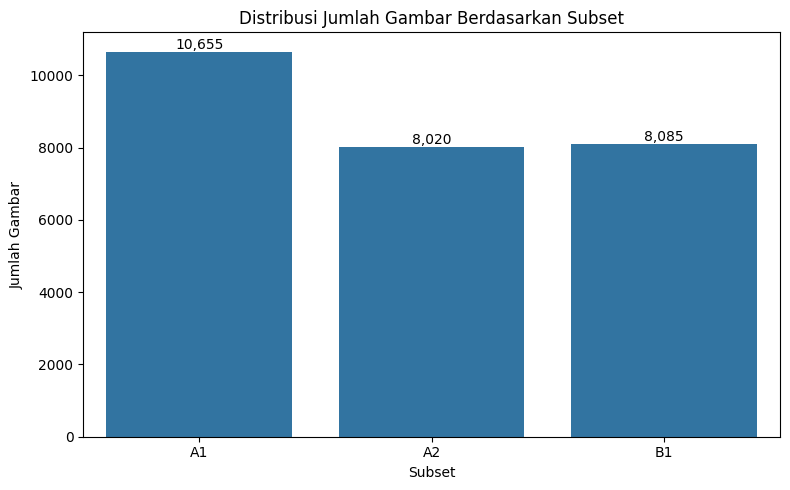

In [ ]:
# ============================================================
# BAGIAN 8.1 - DISTRIBUSI SUBSET
# ============================================================

subset_distribution = (
    metadata["subset"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=subset_distribution.index,
    y=subset_distribution.values
)

plt.title(
    "Distribusi Jumlah Gambar Berdasarkan Subset"
)

plt.xlabel("Subset")
plt.ylabel("Jumlah Gambar")

for i, value in enumerate(
    subset_distribution.values
):

    ax.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

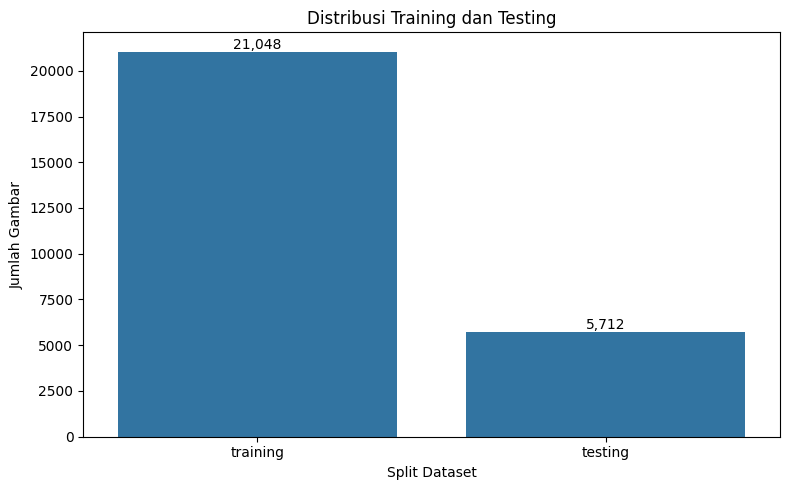

In [ ]:
# ============================================================
# BAGIAN 8.2 - TRAINING VS TESTING
# ============================================================

split_distribution = (
    metadata["split"]
    .value_counts()
    .reindex(
        ["training", "testing"]
    )
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=split_distribution.index,
    y=split_distribution.values
)

plt.title(
    "Distribusi Training dan Testing"
)

plt.xlabel("Split Dataset")
plt.ylabel("Jumlah Gambar")

for i, value in enumerate(
    split_distribution.values
):

    ax.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

split,testing,training
subset,,
A1,2419,8236
A2,1666,6354
B1,1627,6458


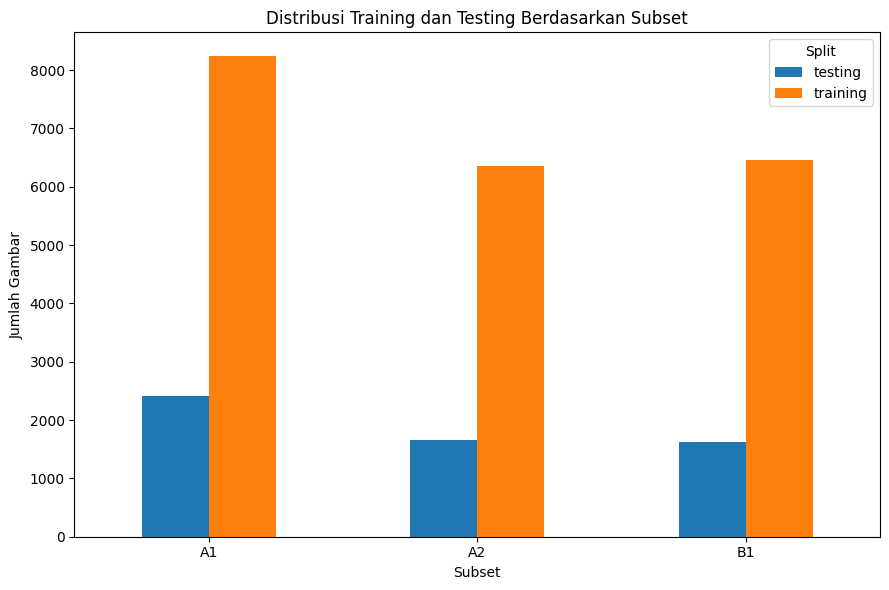

In [ ]:
# ============================================================
# BAGIAN 8.3 - SUBSET VS TRAINING/TESTING
# ============================================================

subset_split = pd.crosstab(
    metadata["subset"],
    metadata["split"]
)

display(subset_split)

subset_split.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title(
    "Distribusi Training dan Testing Berdasarkan Subset"
)

plt.xlabel("Subset")
plt.ylabel("Jumlah Gambar")

plt.xticks(rotation=0)

plt.legend(
    title="Split"
)

plt.tight_layout()
plt.show()

Statistik jumlah gambar per identity:


,jumlah_gambar
count,68.000000
mean,393.529412
std,119.566564
min,27.000000
25%,326.000000
50%,417.000000
75%,476.000000
max,640.000000


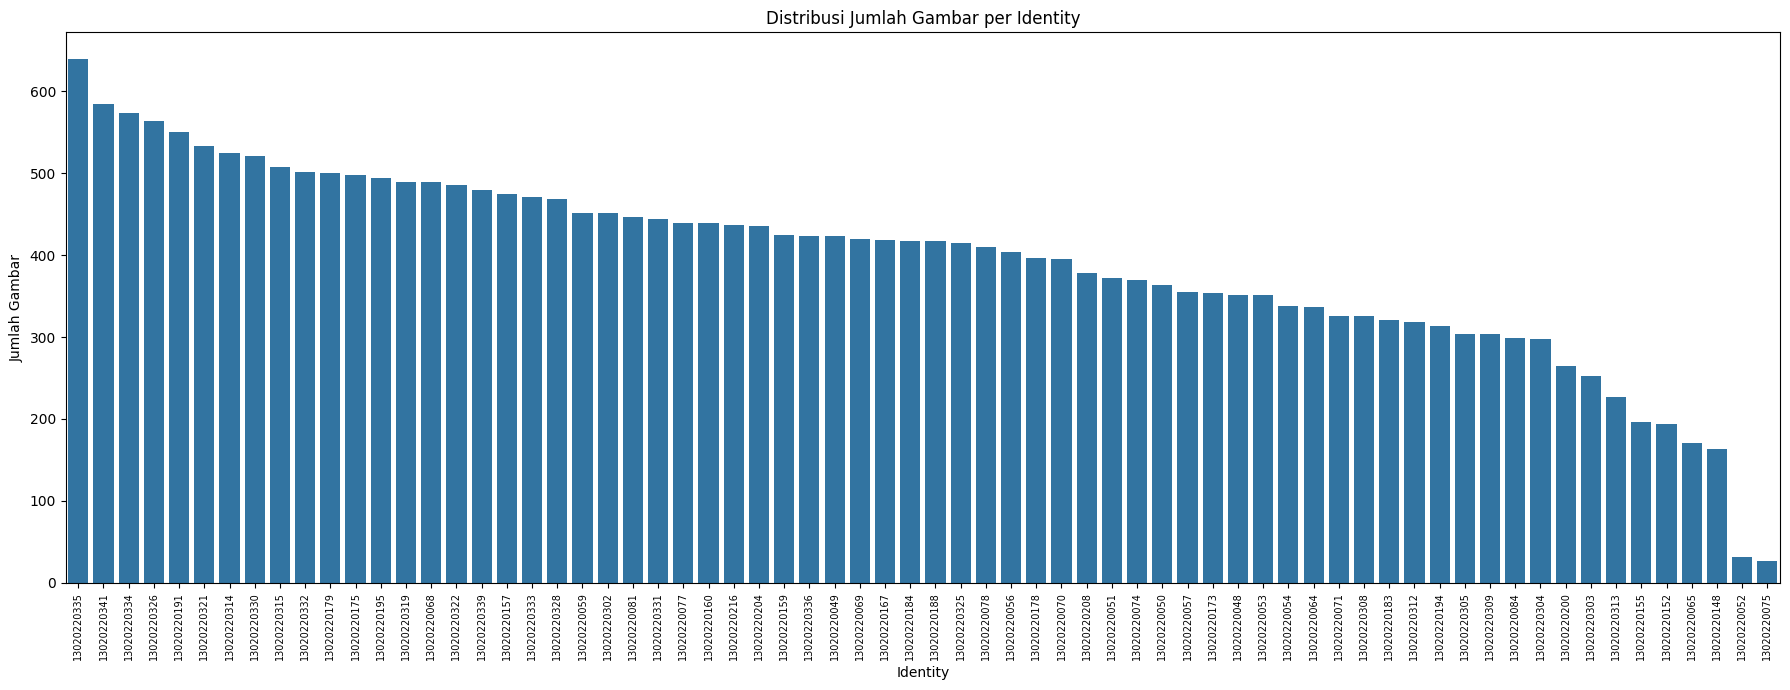

In [ ]:
# ============================================================
# BAGIAN 9 - DISTRIBUSI JUMLAH GAMBAR PER IDENTITY
# ============================================================

identity_distribution = (
    metadata
    .groupby("identity")
    .size()
    .reset_index(
        name="jumlah_gambar"
    )
    .sort_values(
        "jumlah_gambar",
        ascending=False
    )
)

print(
    "Statistik jumlah gambar per identity:"
)

display(
    identity_distribution[
        "jumlah_gambar"
    ].describe()
)

plt.figure(figsize=(18, 7))

sns.barplot(
    data=identity_distribution,
    x="identity",
    y="jumlah_gambar"
)

plt.title(
    "Distribusi Jumlah Gambar per Identity"
)

plt.xlabel("Identity")
plt.ylabel("Jumlah Gambar")

plt.xticks(
    rotation=90,
    fontsize=7
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BAGIAN 10 - PROPERTI GAMBAR
# ============================================================

widths = []
heights = []
channels = []
file_sizes = []

valid_indexes = []

print("=" * 70)
print("MEMBACA PROPERTI GAMBAR")
print("=" * 70)

for index, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Membaca gambar"
):

    image_path = row["image_path"]

    image = cv2.imread(
        image_path
    )

    if image is None:
        continue

    height, width = image.shape[:2]

    if len(image.shape) == 2:
        channel_count = 1
    else:
        channel_count = image.shape[2]

    file_size_kb = (
        os.path.getsize(image_path)
        / 1024
    )

    widths.append(width)
    heights.append(height)
    channels.append(channel_count)
    file_sizes.append(file_size_kb)

    valid_indexes.append(index)


metadata = metadata.loc[
    valid_indexes
].copy()

metadata["width"] = widths
metadata["height"] = heights
metadata["channels"] = channels

metadata["aspect_ratio"] = (
    metadata["width"] /
    metadata["height"]
)

metadata["file_size_kb"] = (
    file_sizes
)

print("\nProperti gambar selesai.")

display(
    metadata.head()
)

MEMBACA PROPERTI GAMBAR


Membaca gambar:   0%|          | 0/26760 [00:00<?, ?it/s]


Properti gambar selesai.


,subset,split,identity,filename,image_path,width,height,channels,aspect_ratio,file_size_kb
0,A1,training,13020220332,tr_13020220332 (13).jpg,/content/IMSFD/A1/training/13020220332/tr_1302...,229,229,3,1.000000,15.000977
1,A1,training,13020220332,tr_13020220332 (126).png,/content/IMSFD/A1/training/13020220332/tr_1302...,1920,1080,3,1.777778,2293.599609
2,A1,training,13020220332,tr_13020220332 (33).jpg,/content/IMSFD/A1/training/13020220332/tr_1302...,243,243,3,1.000000,18.167969
3,A1,training,13020220332,tr_13020220332 (5).png,/content/IMSFD/A1/training/13020220332/tr_1302...,410,410,3,1.000000,196.840820
4,A1,training,13020220332,tr_13020220332 (213).png,/content/IMSFD/A1/training/13020220332/tr_1302...,410,410,3,1.000000,121.583984


In [ ]:
# ============================================================
# BAGIAN 11 - STATISTIK RESOLUSI
# ============================================================

resolution_statistics = metadata[
    [
        "width",
        "height",
        "channels",
        "aspect_ratio",
        "file_size_kb"
    ]
].describe()

display(
    resolution_statistics
)

,width,height,channels,aspect_ratio,file_size_kb
count,26760.000000,26760.000000,26760.0,26760.000000,26760.000000
mean,479.470366,438.173468,3.0,1.030635,245.093117
std,394.435949,233.250279,0.0,0.206694,447.348944
min,1.000000,25.000000,3.0,0.003953,0.608398
25%,248.000000,255.000000,3.0,1.000000,20.158691
50%,410.000000,410.000000,3.0,1.000000,172.320312
75%,615.000000,615.000000,3.0,1.000000,269.768311
max,4176.000000,2784.000000,3.0,3.935484,3195.997070


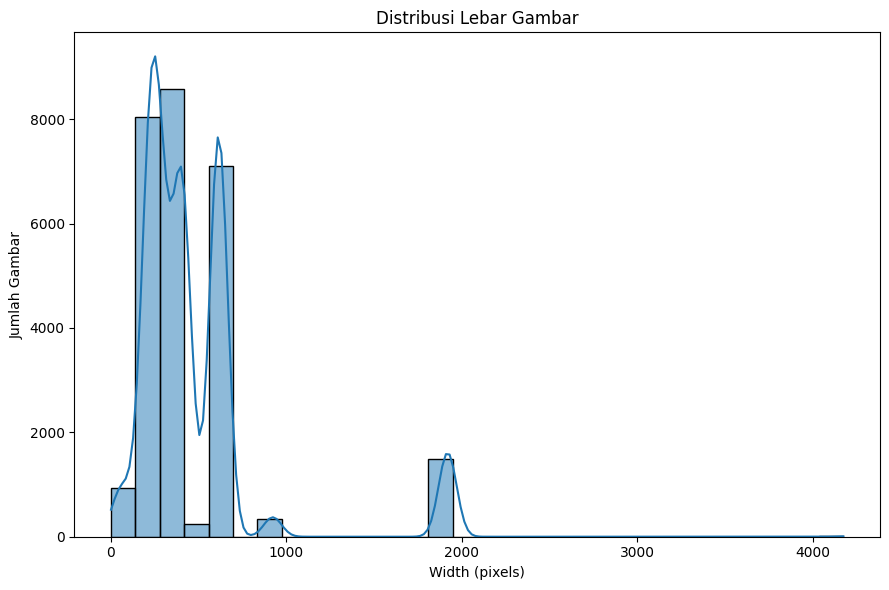

In [ ]:
# ============================================================
# BAGIAN 12 - DISTRIBUSI WIDTH
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["width"],
    bins=30,
    kde=True
)

plt.title(
    "Distribusi Lebar Gambar"
)

plt.xlabel(
    "Width (pixels)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

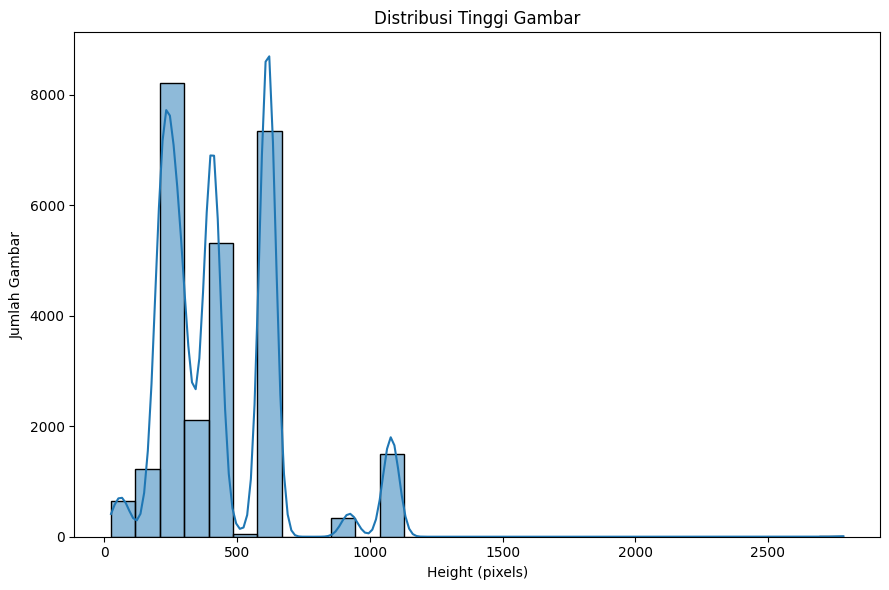

In [ ]:
# ============================================================
# BAGIAN 13 - DISTRIBUSI HEIGHT
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["height"],
    bins=30,
    kde=True
)

plt.title(
    "Distribusi Tinggi Gambar"
)

plt.xlabel(
    "Height (pixels)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

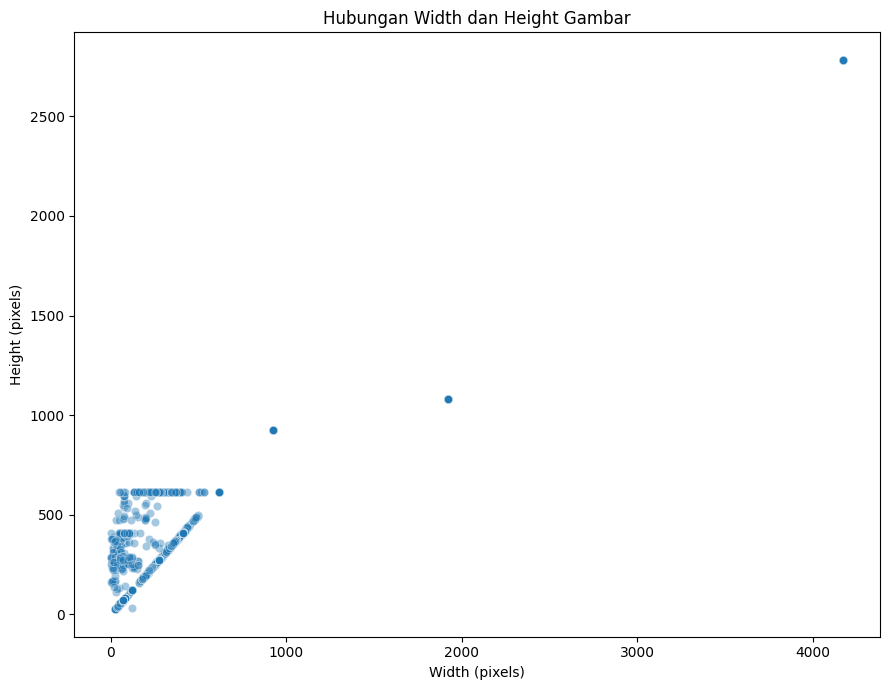

In [ ]:
# ============================================================
# BAGIAN 14 - WIDTH VS HEIGHT
# ============================================================

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=metadata,
    x="width",
    y="height",
    alpha=0.4
)

plt.title(
    "Hubungan Width dan Height Gambar"
)

plt.xlabel(
    "Width (pixels)"
)

plt.ylabel(
    "Height (pixels)"
)

plt.tight_layout()
plt.show()

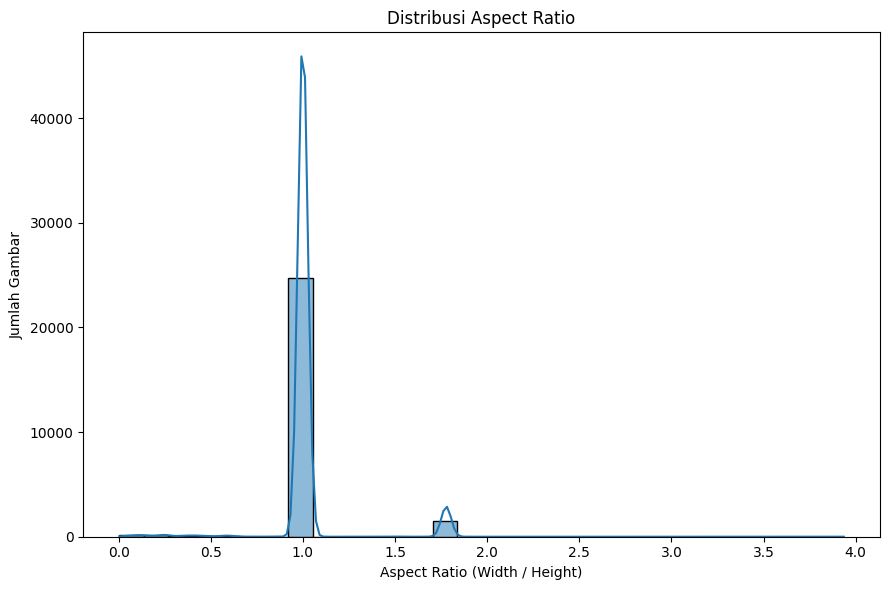

In [ ]:
# ============================================================
# BAGIAN 15 - ASPECT RATIO
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["aspect_ratio"],
    bins=30,
    kde=True
)

plt.title(
    "Distribusi Aspect Ratio"
)

plt.xlabel(
    "Aspect Ratio (Width / Height)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

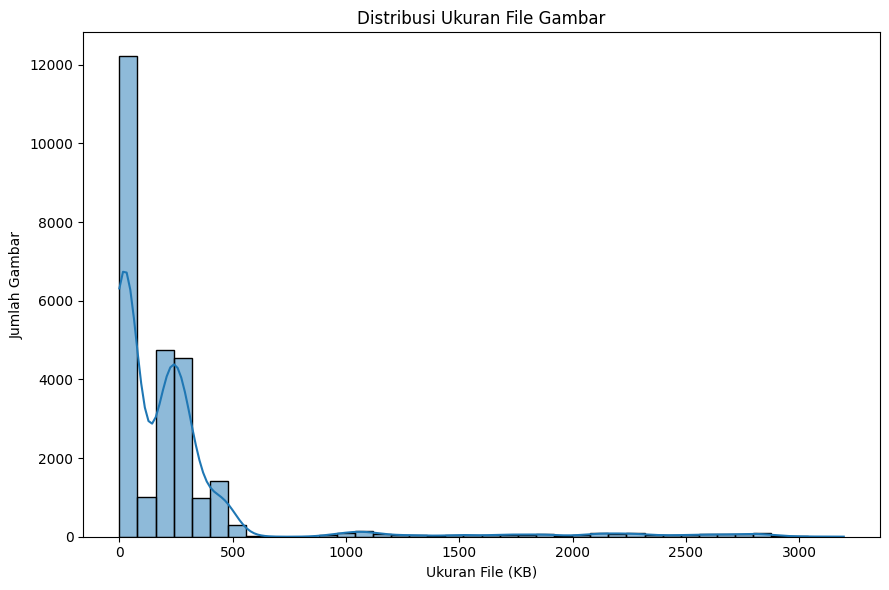

In [ ]:
# ============================================================
# BAGIAN 16 - FILE SIZE
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["file_size_kb"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Ukuran File Gambar"
)

plt.xlabel(
    "Ukuran File (KB)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BAGIAN 17 - BRIGHTNESS, CONTRAST, SHARPNESS
# ============================================================

brightness_values = []
contrast_values = []
sharpness_values = []

for index, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Analisis kualitas gambar"
):

    image = cv2.imread(
        row["image_path"]
    )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    brightness = float(
        np.mean(gray)
    )

    contrast = float(
        np.std(gray)
    )

    sharpness = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    brightness_values.append(
        brightness
    )

    contrast_values.append(
        contrast
    )

    sharpness_values.append(
        sharpness
    )


metadata["brightness_mean"] = (
    brightness_values
)

metadata["contrast"] = (
    contrast_values
)

metadata["sharpness"] = (
    sharpness_values
)

print("Analisis kualitas gambar selesai.")

Analisis kualitas gambar:   0%|          | 0/26760 [00:00<?, ?it/s]

Analisis kualitas gambar selesai.


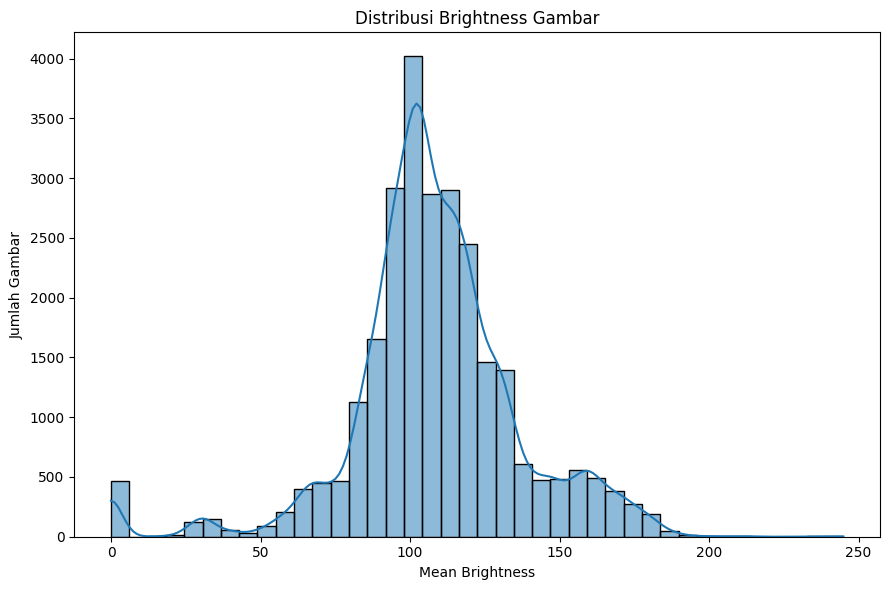

In [ ]:
# ============================================================
# BAGIAN 18 - BRIGHTNESS
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["brightness_mean"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Brightness Gambar"
)

plt.xlabel(
    "Mean Brightness"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

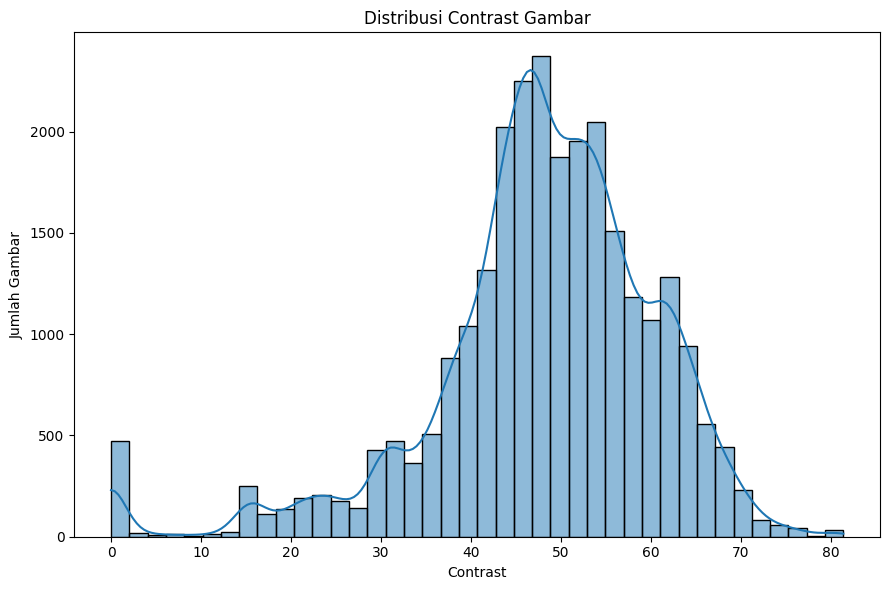

In [ ]:
# ============================================================
# BAGIAN 19 - CONTRAST
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["contrast"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Contrast Gambar"
)

plt.xlabel(
    "Contrast"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

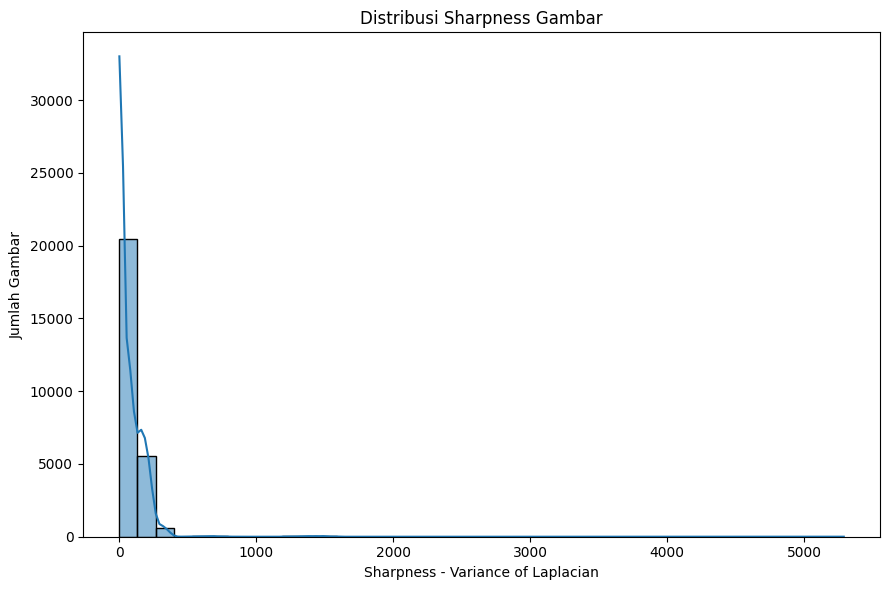

In [ ]:
# ============================================================
# BAGIAN 20 - SHARPNESS
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    metadata["sharpness"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Sharpness Gambar"
)

plt.xlabel(
    "Sharpness - Variance of Laplacian"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BAGIAN 21 - STATISTIK KUALITAS GAMBAR
# ============================================================

quality_statistics = metadata[
    [
        "brightness_mean",
        "contrast",
        "sharpness"
    ]
].describe()

display(
    quality_statistics
)

,brightness_mean,contrast,sharpness
count,26760.000000,26760.000000,26760.000000
mean,108.043527,47.932270,78.776073
std,29.143548,12.856654,129.602939
min,0.000000,0.000000,0.000000
25%,94.676072,42.667699,3.617831
50%,106.224697,48.773915,42.901533
75%,121.594481,55.989683,124.284717
max,244.923868,81.423579,5288.677523


In [ ]:
# ============================================================
# BAGIAN 22 - FACE DETECTION
# ============================================================

haar_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(
    haar_path
)

if face_detector.empty():

    raise RuntimeError(
        "Haar Cascade gagal dimuat."
    )

print(
    "Face detector berhasil dimuat."
)

Face detector berhasil dimuat.


In [ ]:
# ============================================================
# BAGIAN 23 - MENJALANKAN FACE DETECTION
# ============================================================

face_detected = []
face_x = []
face_y = []
face_width = []
face_height = []
face_area = []
face_area_ratio = []
face_center_x = []
face_center_y = []

for index, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Face Detection"
):

    image = cv2.imread(
        row["image_path"]
    )

    if image is None:

        face_detected.append(False)
        face_x.append(np.nan)
        face_y.append(np.nan)
        face_width.append(np.nan)
        face_height.append(np.nan)
        face_area.append(np.nan)
        face_area_ratio.append(np.nan)
        face_center_x.append(np.nan)
        face_center_y.append(np.nan)

        continue

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) > 0:

        # Ambil wajah terbesar
        x, y, w, h = max(
            faces,
            key=lambda box:
            box[2] * box[3]
        )

        image_height, image_width = (
            image.shape[:2]
        )

        area = w * h

        image_area = (
            image_width *
            image_height
        )

        area_ratio = (
            area /
            image_area
        )

        center_x = (
            x + w / 2
        )

        center_y = (
            y + h / 2
        )

        face_detected.append(True)
        face_x.append(x)
        face_y.append(y)
        face_width.append(w)
        face_height.append(h)
        face_area.append(area)
        face_area_ratio.append(
            area_ratio
        )
        face_center_x.append(
            center_x
        )
        face_center_y.append(
            center_y
        )

    else:

        face_detected.append(False)
        face_x.append(np.nan)
        face_y.append(np.nan)
        face_width.append(np.nan)
        face_height.append(np.nan)
        face_area.append(np.nan)
        face_area_ratio.append(np.nan)
        face_center_x.append(np.nan)
        face_center_y.append(np.nan)


metadata["face_detected"] = (
    face_detected
)

metadata["face_x"] = face_x
metadata["face_y"] = face_y

metadata["face_width"] = (
    face_width
)

metadata["face_height"] = (
    face_height
)

metadata["face_area"] = (
    face_area
)

metadata["face_area_ratio"] = (
    face_area_ratio
)

metadata["face_center_x"] = (
    face_center_x
)

metadata["face_center_y"] = (
    face_center_y
)

print("Face detection selesai.")

Face Detection:   0%|          | 0/26760 [00:00<?, ?it/s]

Face detection selesai.


In [ ]:
# ============================================================
# BAGIAN 24 - HASIL FACE DETECTION
# ============================================================

total = len(metadata)

detected = int(
    metadata["face_detected"].sum()
)

not_detected = (
    total - detected
)

detection_rate = (
    detected /
    total *
    100
)

print("=" * 70)
print("HASIL FACE DETECTION")
print("=" * 70)

print(
    f"\nTotal gambar       : {total:,}"
)

print(
    f"Face terdeteksi    : {detected:,}"
)

print(
    f"Face tidak terdeteksi : {not_detected:,}"
)

print(
    f"Detection rate     : "
    f"{detection_rate:.2f}%"
)

HASIL FACE DETECTION

Total gambar       : 26,760
Face terdeteksi    : 24,107
Face tidak terdeteksi : 2,653
Detection rate     : 90.09%


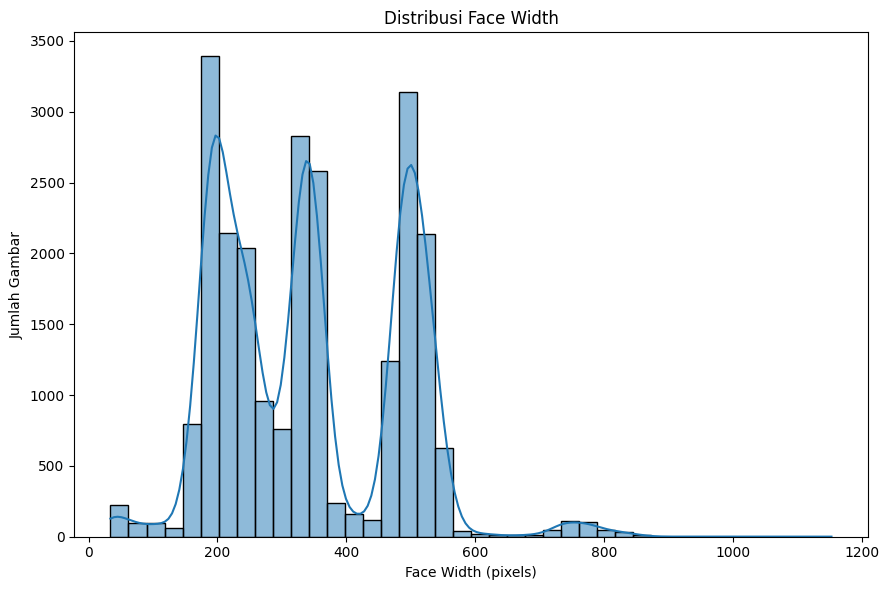

In [ ]:
# ============================================================
# BAGIAN 25 - FACE WIDTH
# ============================================================

face_data = metadata[
    metadata["face_detected"] == True
].copy()

plt.figure(figsize=(9, 6))

sns.histplot(
    face_data["face_width"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Face Width"
)

plt.xlabel(
    "Face Width (pixels)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

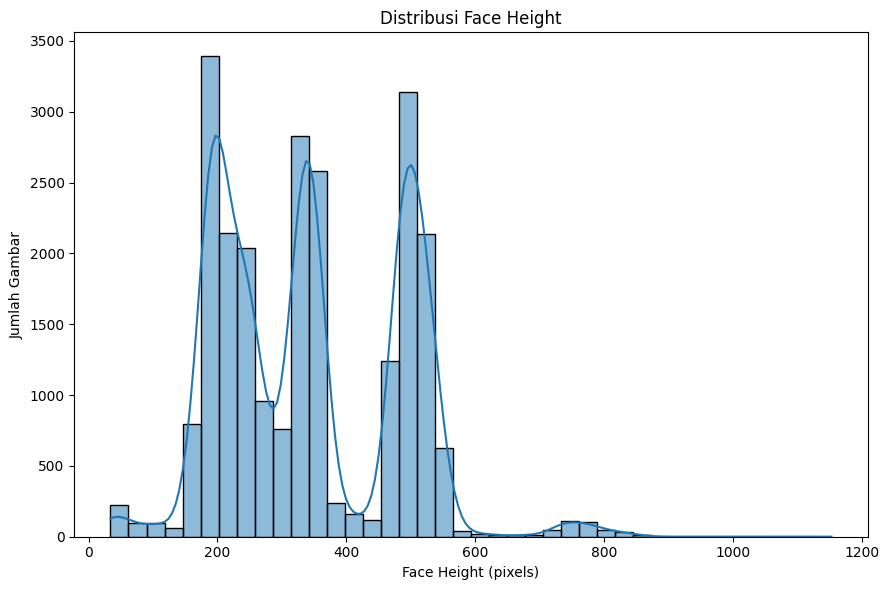

In [ ]:
# ============================================================
# BAGIAN 26 - FACE HEIGHT
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    face_data["face_height"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Face Height"
)

plt.xlabel(
    "Face Height (pixels)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

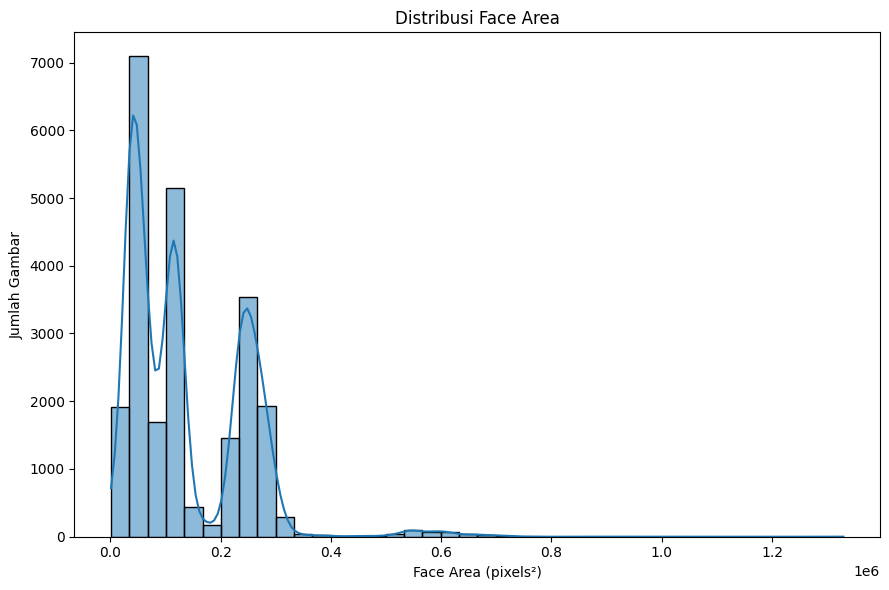

In [ ]:
# ============================================================
# BAGIAN 27 - FACE AREA
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    face_data["face_area"],
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Face Area"
)

plt.xlabel(
    "Face Area (pixels²)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

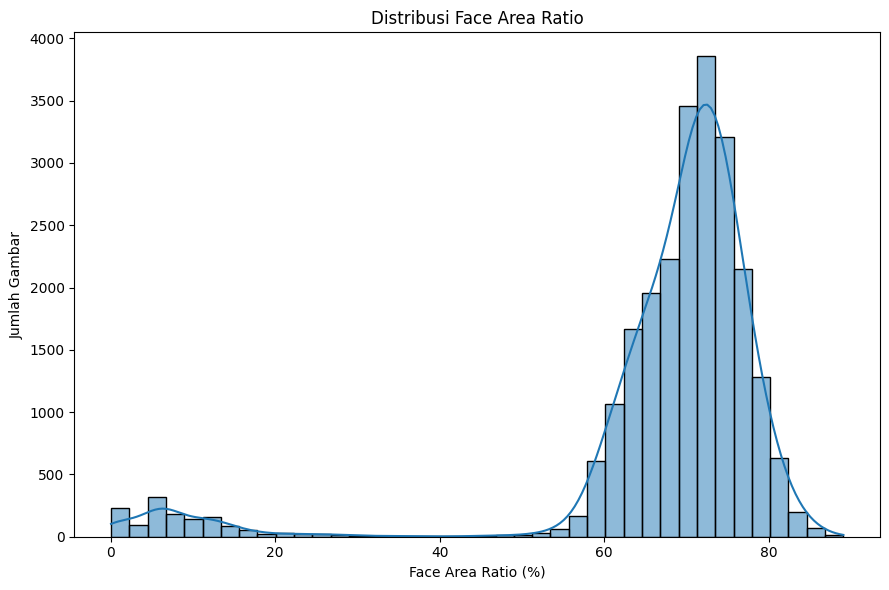

In [ ]:
# ============================================================
# BAGIAN 28 - FACE AREA RATIO
# ============================================================

plt.figure(figsize=(9, 6))

sns.histplot(
    face_data["face_area_ratio"] * 100,
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Face Area Ratio"
)

plt.xlabel(
    "Face Area Ratio (%)"
)

plt.ylabel(
    "Jumlah Gambar"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BAGIAN 29 - STATISTIK FACE SIZE
# ============================================================

face_size_statistics = face_data[
    [
        "face_width",
        "face_height",
        "face_area",
        "face_area_ratio"
    ]
].describe()

display(
    face_size_statistics
)

,face_width,face_height,face_area,face_area_ratio
count,24107.000000,24107.000000,2.410700e+04,24107.000000
mean,342.322562,342.322562,1.366598e+05,0.671632
std,139.556034,139.556034,1.075794e+05,0.155995
min,34.000000,34.000000,1.156000e+03,0.000625
25%,219.000000,219.000000,4.796100e+04,0.658341
50%,331.000000,331.000000,1.095610e+05,0.709430
75%,485.000000,485.000000,2.352250e+05,0.745485
max,1153.000000,1153.000000,1.329409e+06,0.890498


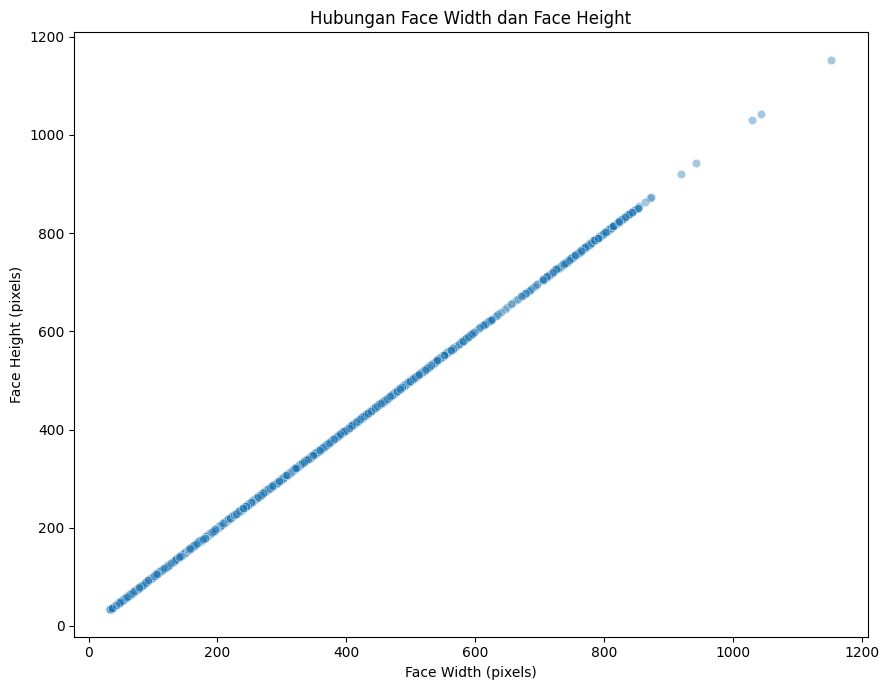

In [ ]:
# ============================================================
# BAGIAN 30 - FACE WIDTH VS FACE HEIGHT
# ============================================================

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=face_data,
    x="face_width",
    y="face_height",
    alpha=0.4
)

plt.title(
    "Hubungan Face Width dan Face Height"
)

plt.xlabel(
    "Face Width (pixels)"
)

plt.ylabel(
    "Face Height (pixels)"
)

plt.tight_layout()
plt.show()

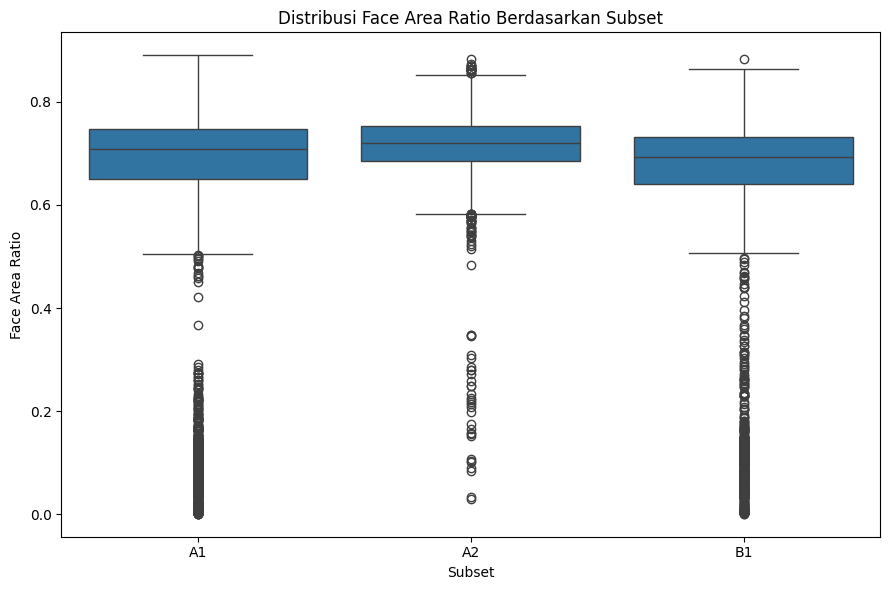

In [ ]:
# ============================================================
# BAGIAN 31 - FACE SIZE BERDASARKAN SUBSET
# ============================================================

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=face_data,
    x="subset",
    y="face_area_ratio"
)

plt.title(
    "Distribusi Face Area Ratio Berdasarkan Subset"
)

plt.xlabel(
    "Subset"
)

plt.ylabel(
    "Face Area Ratio"
)

plt.tight_layout()
plt.show()

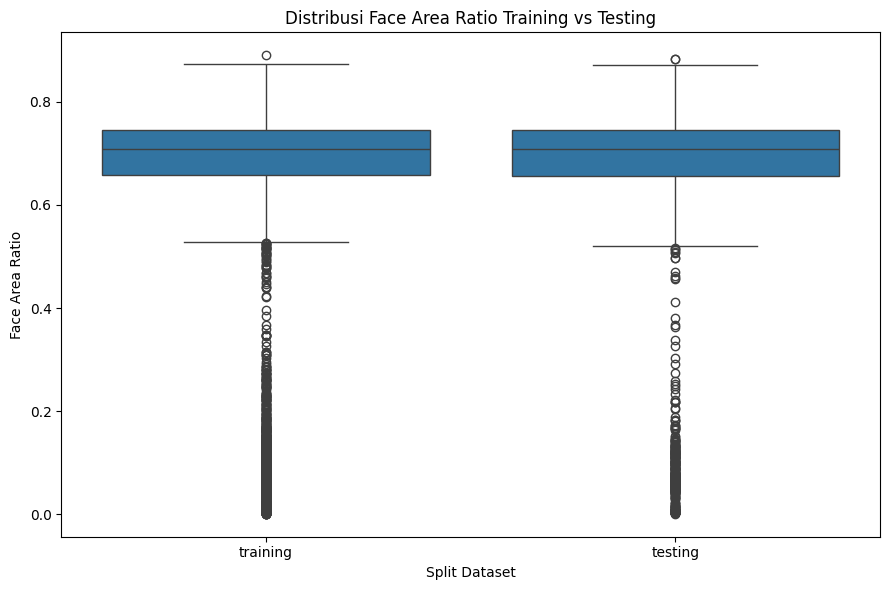

In [ ]:
# ============================================================
# BAGIAN 32 - FACE SIZE TRAINING VS TESTING
# ============================================================

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=face_data,
    x="split",
    y="face_area_ratio"
)

plt.title(
    "Distribusi Face Area Ratio Training vs Testing"
)

plt.xlabel(
    "Split Dataset"
)

plt.ylabel(
    "Face Area Ratio"
)

plt.tight_layout()
plt.show()

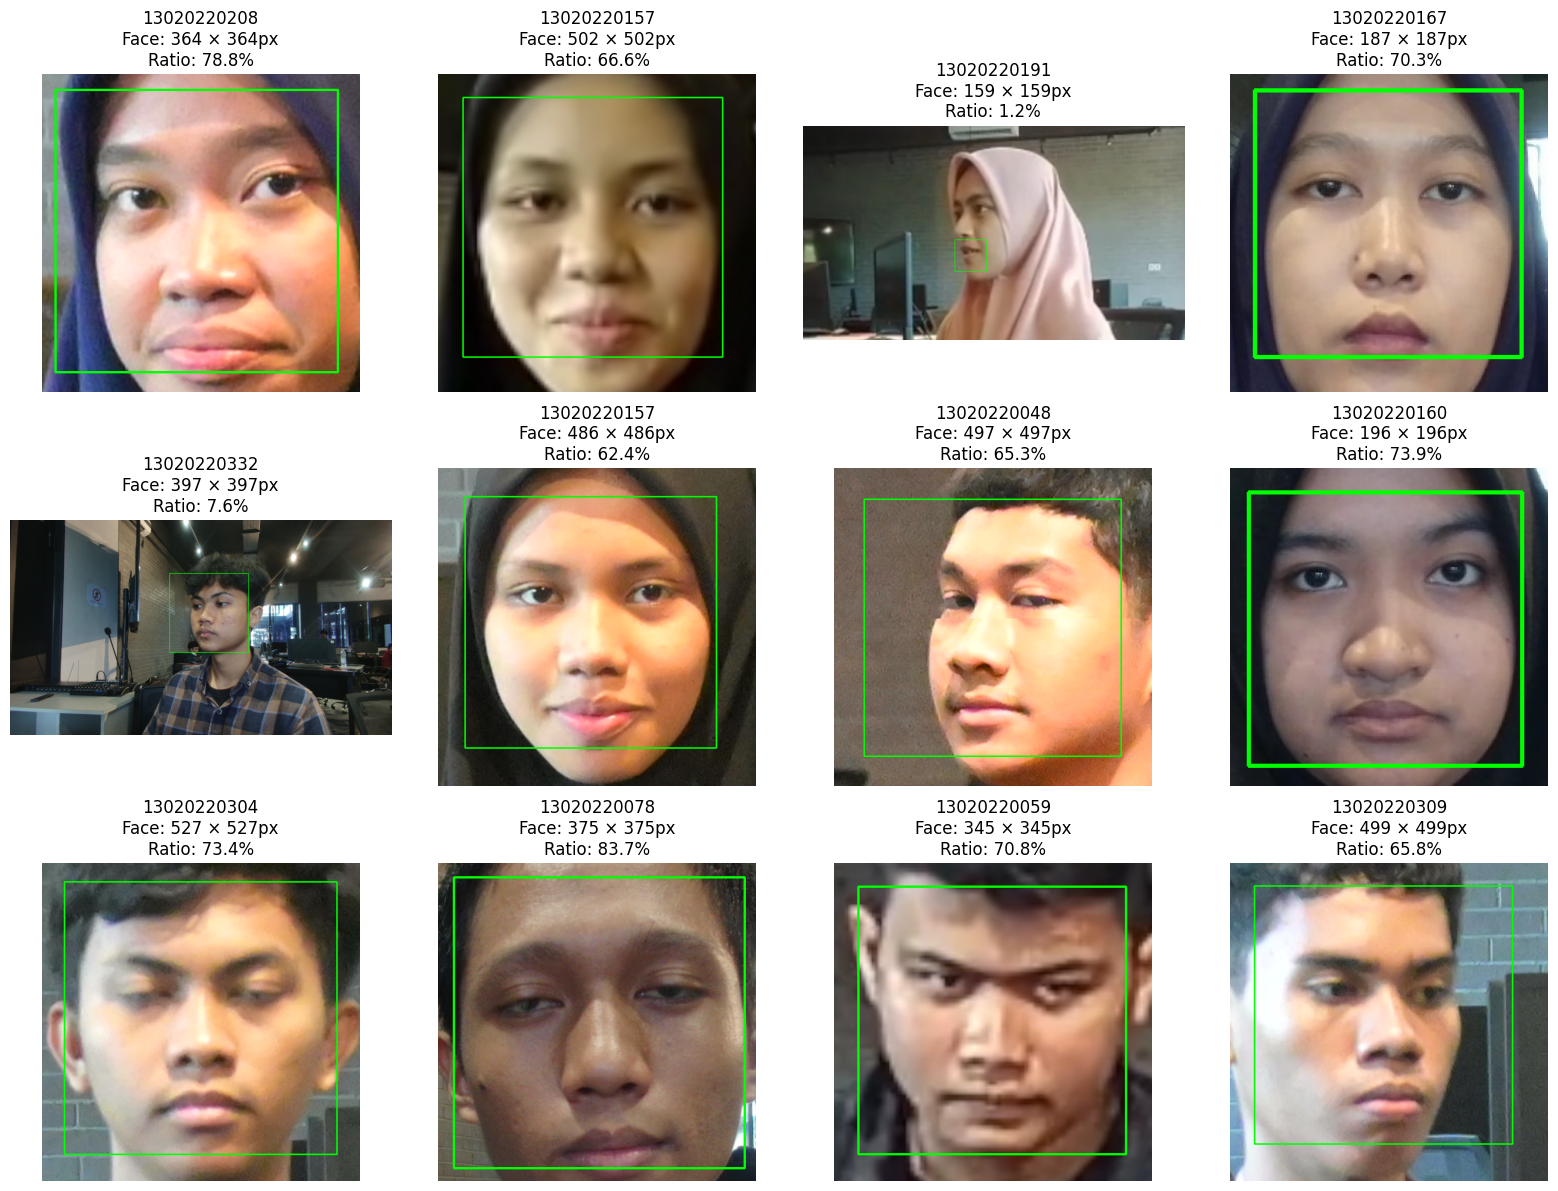

In [ ]:
# ============================================================
# BAGIAN 33 - SAMPLE BOUNDING BOX
# ============================================================

sample = face_data.sample(
    n=min(12, len(face_data)),
    random_state=42
)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, (_, row) in zip(
    axes,
    sample.iterrows()
):

    image = cv2.imread(
        row["image_path"]
    )

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    x = int(row["face_x"])
    y = int(row["face_y"])
    w = int(row["face_width"])
    h = int(row["face_height"])

    cv2.rectangle(
        image_rgb,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    ax.imshow(
        image_rgb
    )

    ax.set_title(
        f"{row['identity']}\n"
        f"Face: {w} × {h}px\n"
        f"Ratio: "
        f"{row['face_area_ratio'] * 100:.1f}%"
    )

    ax.axis("off")


for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

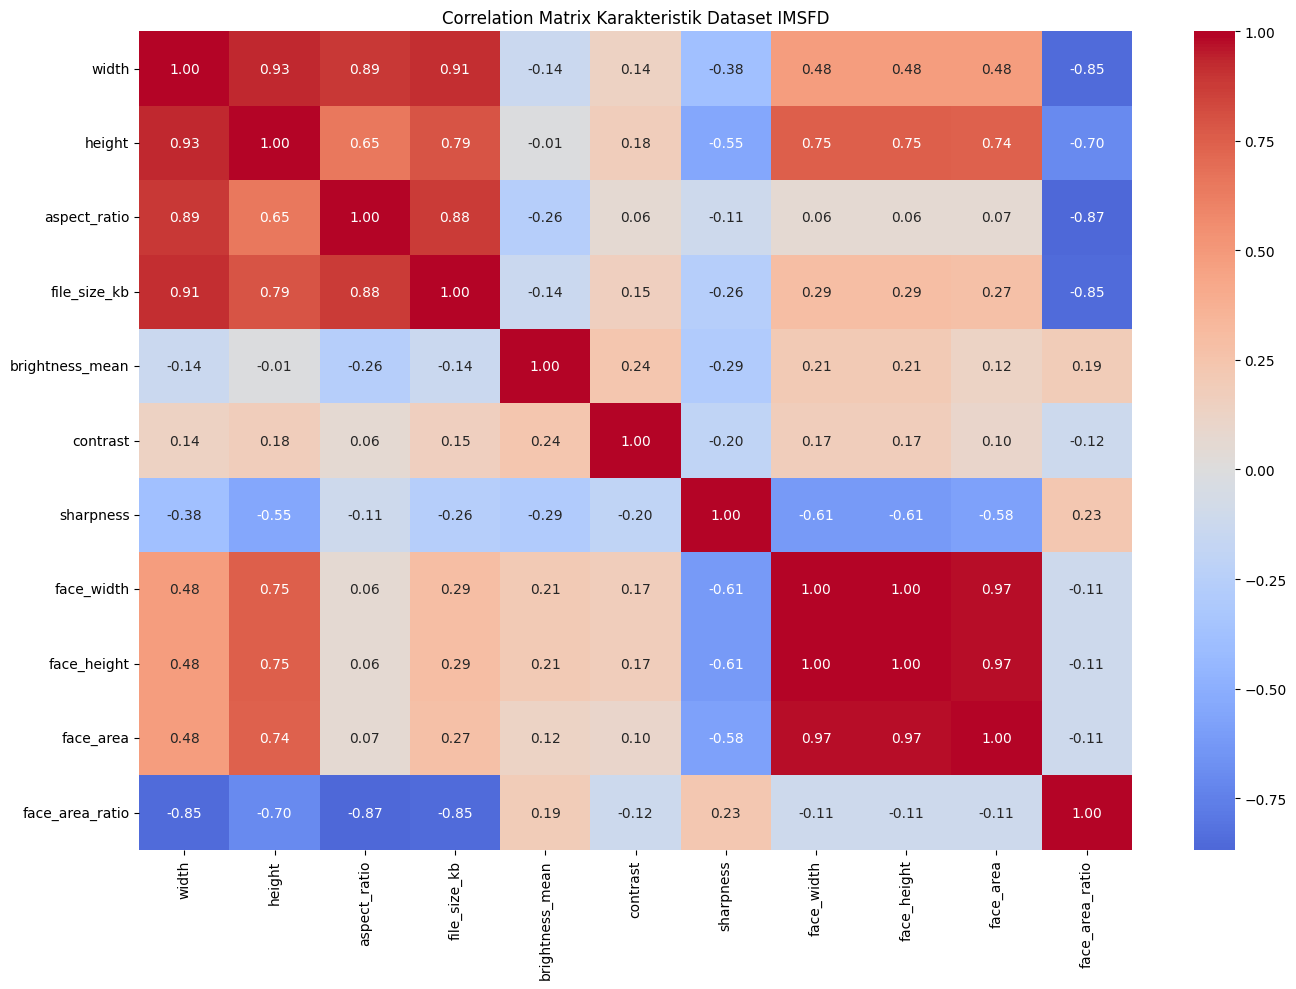

In [ ]:
# ============================================================
# BAGIAN 34 - CORRELATION MATRIX
# ============================================================

correlation_columns = [
    "width",
    "height",
    "aspect_ratio",
    "file_size_kb",
    "brightness_mean",
    "contrast",
    "sharpness",
    "face_width",
    "face_height",
    "face_area",
    "face_area_ratio"
]

correlation_matrix = face_data[
    correlation_columns
].corr()

plt.figure(
    figsize=(14, 10)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix Karakteristik Dataset IMSFD"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BAGIAN 35 - SIMPAN METADATA
# ============================================================

OUTPUT_PATH = "/content/EDA_IMSFD"

os.makedirs(
    OUTPUT_PATH,
    exist_ok=True
)

metadata_path = os.path.join(
    OUTPUT_PATH,
    "metadata_IMSFD.csv"
)

face_metadata_path = os.path.join(
    OUTPUT_PATH,
    "metadata_face_detected.csv"
)

metadata.to_csv(
    metadata_path,
    index=False
)

face_data.to_csv(
    face_metadata_path,
    index=False
)

print(
    "Metadata berhasil disimpan:"
)

print(
    metadata_path
)

print(
    face_metadata_path
)

Metadata berhasil disimpan:
/content/EDA_IMSFD/metadata_IMSFD.csv
/content/EDA_IMSFD/metadata_face_detected.csv


In [ ]:
# ============================================================
# BAGIAN 36 - DOWNLOAD METADATA
# ============================================================

from google.colab import files

files.download(
    "/content/EDA_IMSFD/metadata_IMSFD.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>